In [8]:
!pip install kagglehub pandas numpy matplotlib seaborn scikit-learn

In [9]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

In [10]:
# 1.Download latest version
path = kagglehub.dataset_download("andrewmvd/heart-failure-clinical-data")

print("Dataset Folder:", path)

Using Colab cache for faster access to the 'heart-failure-clinical-data' dataset.
Dataset Folder: /kaggle/input/heart-failure-clinical-data


In [12]:
#2.
csv_path = os.path.join(path, "heart_failure_clinical_records_dataset.csv")

df = pd.read_csv(csv_path)

print(df.head())

    age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0  75.0        0                       582         0                 20   
1  55.0        0                      7861         0                 38   
2  65.0        0                       146         0                 20   
3  50.0        1                       111         0                 20   
4  65.0        1                       160         1                 20   

   high_blood_pressure  platelets  serum_creatinine  serum_sodium  sex  \
0                    1  265000.00               1.9           130    1   
1                    0  263358.03               1.1           136    1   
2                    0  162000.00               1.3           129    1   
3                    0  210000.00               1.9           137    1   
4                    0  327000.00               2.7           116    0   

   smoking  time  DEATH_EVENT  
0        0     4            1  
1        0     6            1  
2       

In [13]:
#3.
print("Shape:", df.shape)

print("\nColumns")
print(df.columns)

print("\nData Types")
print(df.dtypes)

print("\nMissing Values")
print(df.isnull().sum())

Shape: (299, 13)

Columns
Index(['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes',
       'ejection_fraction', 'high_blood_pressure', 'platelets',
       'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time',
       'DEATH_EVENT'],
      dtype='object')

Data Types
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object

Missing Values
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creat

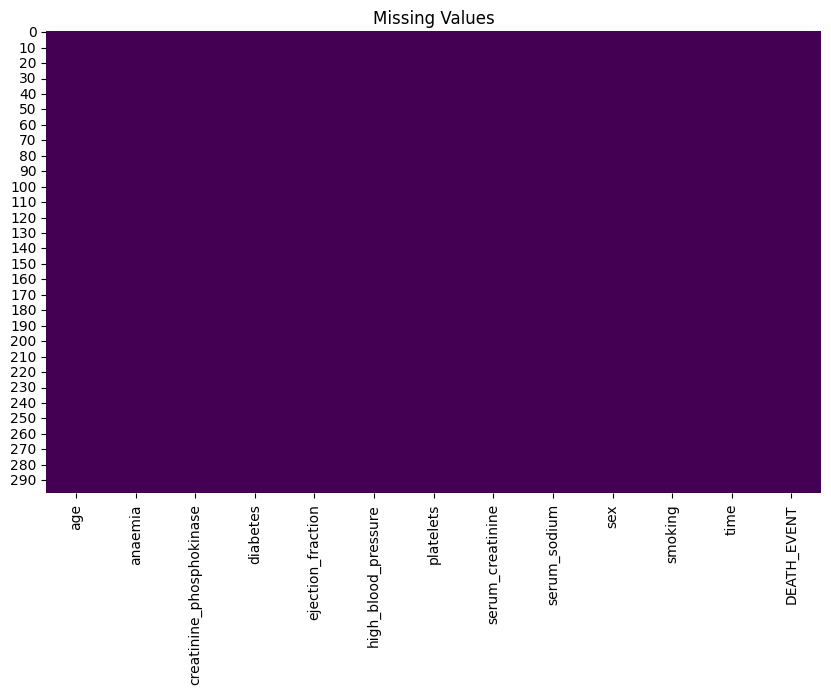

In [14]:
#4
plt.figure(figsize=(10,6))
sns.heatmap(df.isnull(), cmap="viridis", cbar=False)
plt.title("Missing Values")
plt.show()

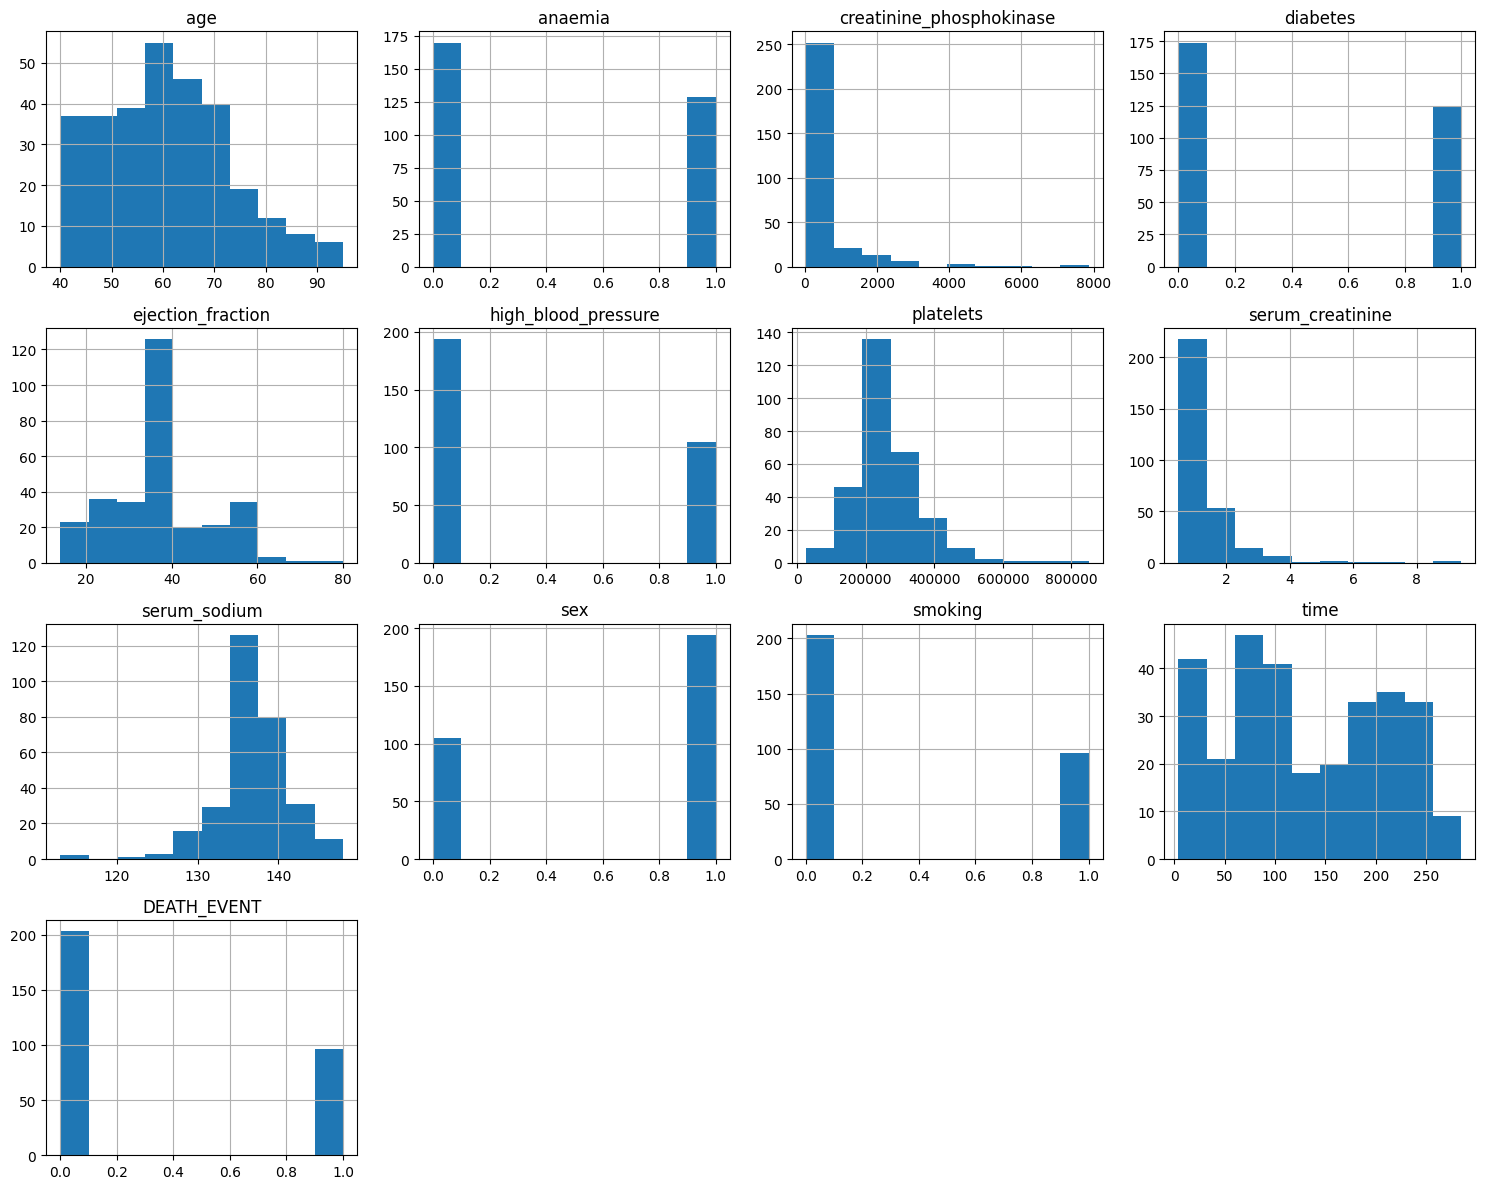

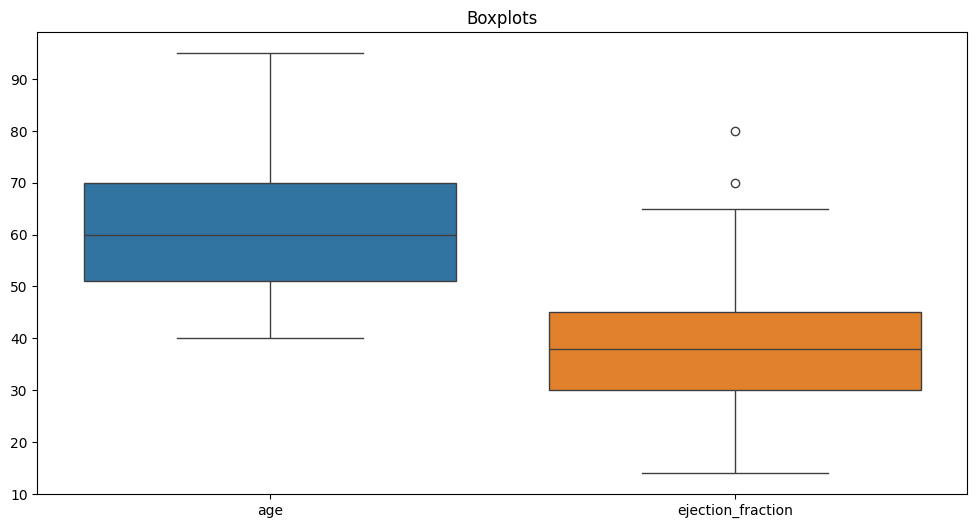

In [15]:
#5.
df.hist(figsize=(15,12))
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
sns.boxplot(data=df[['age','ejection_fraction']])
plt.title("Boxplots")
plt.show()

In [16]:
#6.
num_cols = df.select_dtypes(include=np.number).columns
num_imputer = SimpleImputer(strategy='median')
df[num_cols] = num_imputer.fit_transform(df[num_cols])


cat_cols = df.select_dtypes(include='object').columns

if len(cat_cols) > 0:
    cat_imputer = SimpleImputer(strategy='most_frequent')
    df[cat_cols] = cat_imputer.fit_transform(df[cat_cols])



In [17]:
#7.
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("New Shape:", df.shape)

New Shape: (224, 13)


In [18]:
#8.
if 'age' in df.columns:
    df.loc[df['age'] < 0, 'age'] = df['age'].median()

In [19]:
#9.
df['age_group'] = pd.cut(
    df['age'],
    bins=[0,40,60,100],
    labels=['<40','40-60','>60']
)

df['risk_score'] = (
    df['ejection_fraction'] *
    df['serum_creatinine']
)

df['risk_score'] = (
    df['risk_score'] -
    df['risk_score'].min()
) / (
    df['risk_score'].max() -
    df['risk_score'].min()
)

In [20]:
#10.
encoder = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = encoder.fit_transform(df[col])

# Encode age_group as well
df['age_group'] = LabelEncoder().fit_transform(df['age_group'])

In [21]:
#11.
scaler = MinMaxScaler()

numeric_columns = df.select_dtypes(include=np.number).columns

df[numeric_columns] = scaler.fit_transform(df[numeric_columns])

In [22]:
#12.
original_df = pd.read_csv(csv_path)

print("Before Cleaning")
print(original_df.describe())

print("\nAfter Cleaning")
print(df.describe())

Before Cleaning
              age     anaemia  creatinine_phosphokinase    diabetes  \
count  299.000000  299.000000                299.000000  299.000000   
mean    60.833893    0.431438                581.839465    0.418060   
std     11.894809    0.496107                970.287881    0.494067   
min     40.000000    0.000000                 23.000000    0.000000   
25%     51.000000    0.000000                116.500000    0.000000   
50%     60.000000    0.000000                250.000000    0.000000   
75%     70.000000    1.000000                582.000000    1.000000   
max     95.000000    1.000000               7861.000000    1.000000   

       ejection_fraction  high_blood_pressure      platelets  \
count         299.000000           299.000000     299.000000   
mean           38.083612             0.351171  263358.029264   
std            11.834841             0.478136   97804.236869   
min            14.000000             0.000000   25100.000000   
25%            30.000000

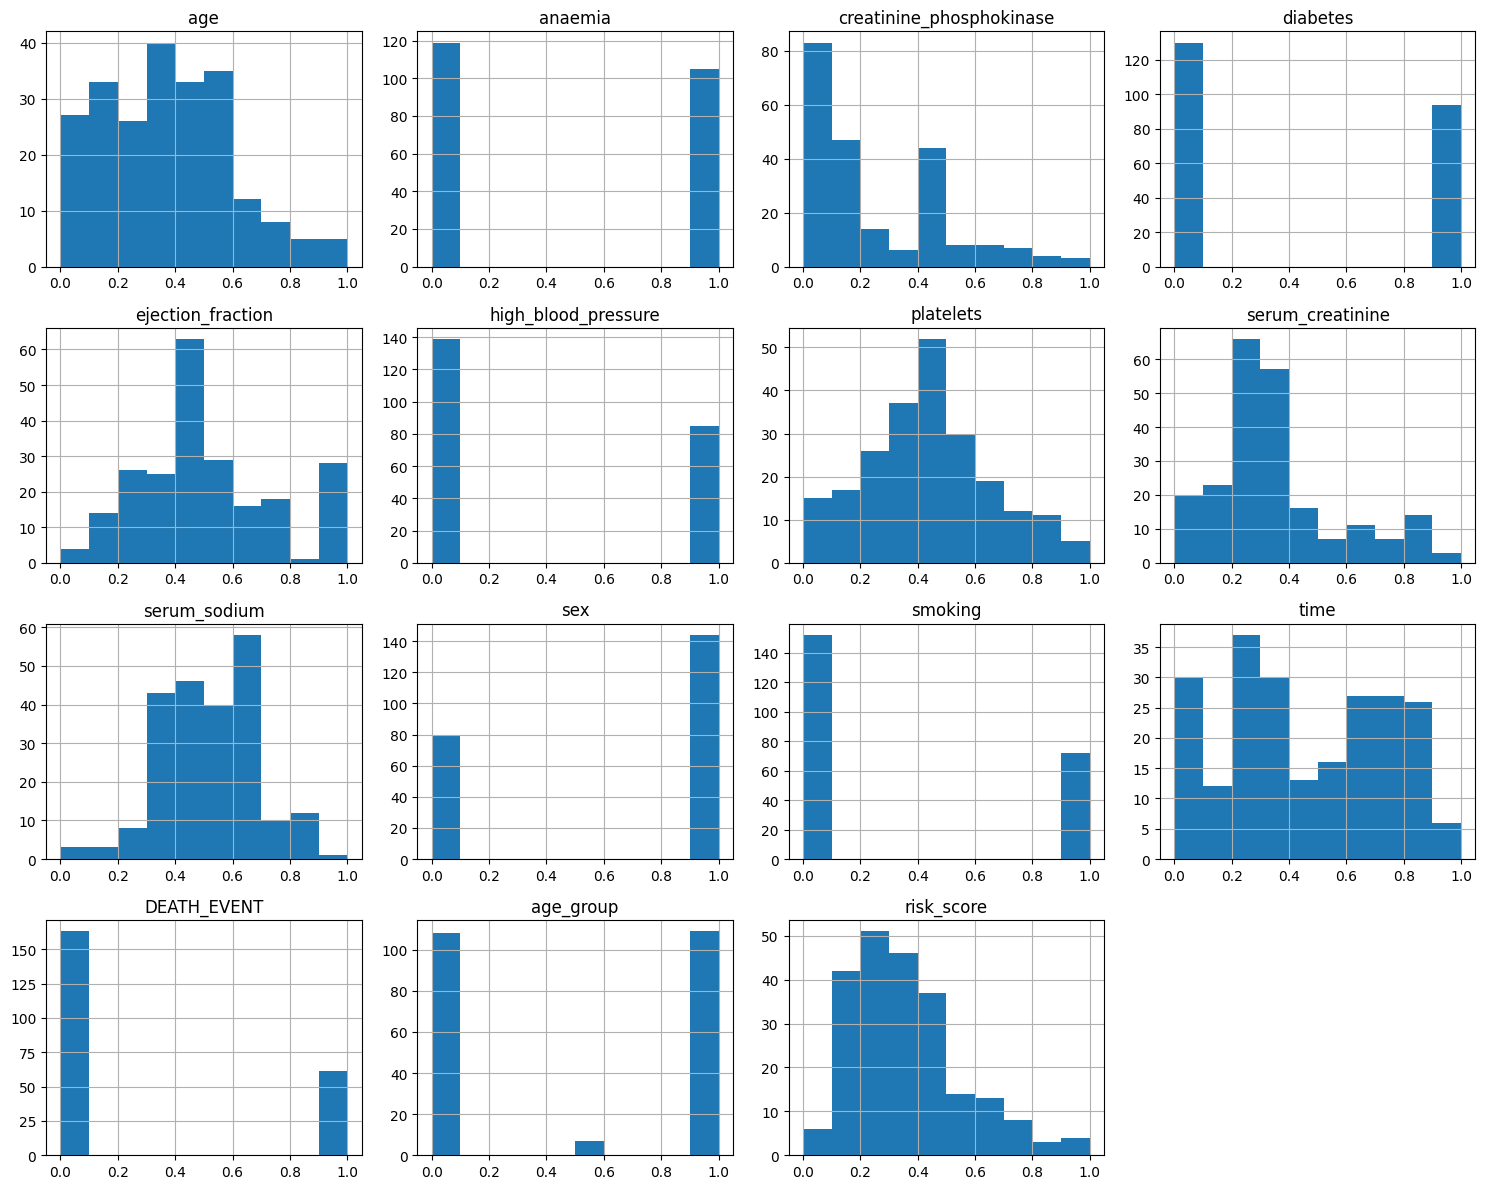

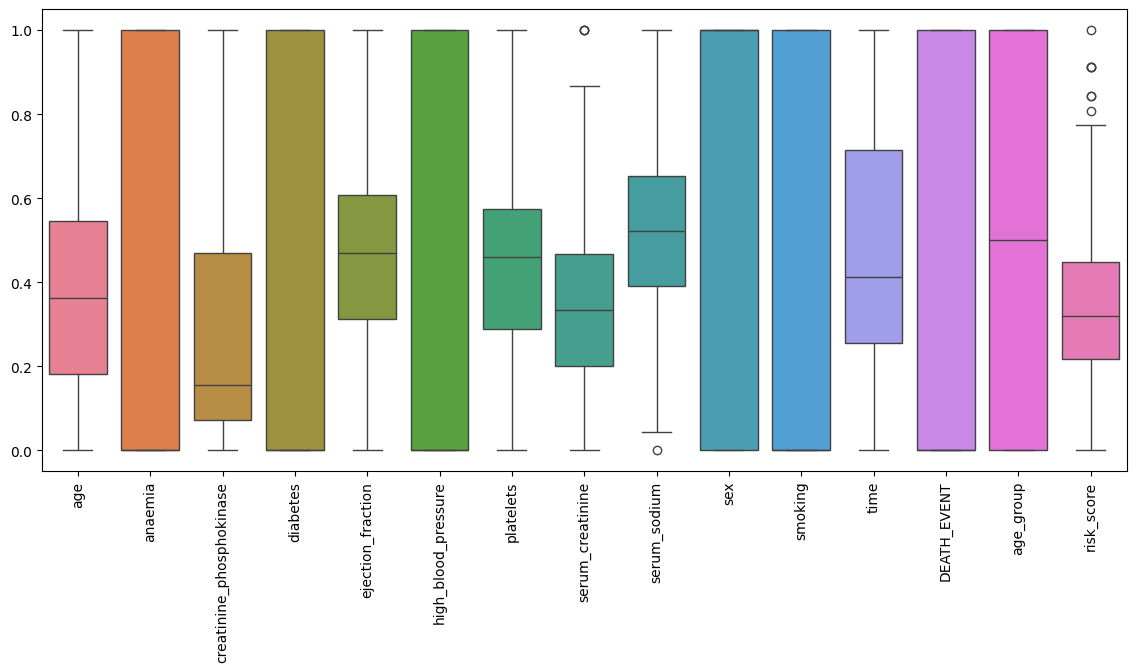

In [23]:
#13.
df.hist(figsize=(15,12))
plt.tight_layout()
plt.show()

plt.figure(figsize=(14,6))
sns.boxplot(data=df[numeric_columns])
plt.xticks(rotation=90)
plt.show()

In [24]:
#14.
print(df.isnull().sum())

if df.isnull().sum().sum() == 0:
    print("No missing values remain.")
else:
    print("Missing values still exist.")

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
age_group                   0
risk_score                  0
dtype: int64
No missing values remain.


In [26]:
# Save to the local working directory since /kaggle/input is read-only
output_path = "cleaned_heart_failure_dataset.csv"

df.to_csv(output_path, index=False)

print("Saved Successfully!")
print(f"File saved at: {os.path.abspath(output_path)}")

Saved Successfully!
File saved at: /content/cleaned_heart_failure_dataset.csv
